In [1]:
import os
from dotenv import load_dotenv
from google import genai

load_dotenv(override=True)

api_key = os.getenv("GEMINI_API_KEY")

if not api_key:
    raise ValueError("API Key not found in .env")

client = genai.Client(api_key=api_key)

from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser , PydanticOutputParser

from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage

llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0)

# **SQL DATABASE AGENT**


In [8]:

from langchain_community.utilities.sql_database import SQLDatabase

sql_db = SQLDatabase.from_uri(
    "sqlite:///E:/LangChain_Practice/CH3/sales.db"
)

print(sql_db.get_usable_table_names())


['orders']


In [9]:
print(sql_db.get_usable_table_names())

['orders']


In [10]:
from langchain_community.agent_toolkits.sql.toolkit import SQLDatabaseToolkit

toolkit = SQLDatabaseToolkit(db=sql_db, llm=llm)
toolkit.get_tools()

[QuerySQLDatabaseTool(description="Input to this tool is a detailed and correct SQL query, output is a result from the database. If the query is not correct, an error message will be returned. If an error is returned, rewrite the query, check the query, and try again. If you encounter an issue with Unknown column 'xxxx' in 'field list', use sql_db_schema to query the correct table fields.", db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x000002F5BB9D4800>),
 InfoSQLDatabaseTool(description='Input to this tool is a comma-separated list of tables, output is the schema and sample rows for those tables. Be sure that the tables actually exist by calling sql_db_list_tables first! Example Input: table1, table2, table3', db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x000002F5BB9D4800>),
 ListSQLDatabaseTool(db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x000002F5BB9D4800>),
 QuerySQLCheckerTool(description='Use this tool to 

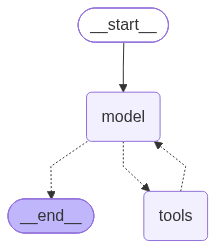

In [12]:
from langchain.agents import create_agent

tools = toolkit.get_tools()

agent = create_agent(
    model=llm,
    tools=tools,
    system_prompt=(
        "You are a SQL assistant. "
        "Use the provided SQL tools to answer questions about the database. "
        "Inspect the schema before writing queries. "
        "Do not modify or delete database records."
    )
)

agent

In [13]:
example_query = "How much total sales we made for Tablet"

events = agent.stream(
    {"messages": [("user", example_query)]},
    stream_mode="values",
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

How much total sales we made for Tablet
================================== Ai Message ==================================

[]
Tool Calls:
  sql_db_list_tables (call_4141172)
 Call ID: call_4141172
  Args:
    tool_input:
================================= Tool Message =================================
Name: sql_db_list_tables

orders
================================== Ai Message ==================================

[]
Tool Calls:
  sql_db_schema (call_4101830)
 Call ID: call_4101830
  Args:
    table_names: orders
================================= Tool Message =================================
Name: sql_db_schema


CREATE TABLE orders (
	id INTEGER, 
	customer_name TEXT NOT NULL, 
	product_name TEXT NOT NULL, 
	quantity INTEGER NOT NULL, 
	price REAL NOT NULL, 
	total REAL NOT NULL, 
	PRIMARY KEY (id)
)

/*
3 rows from orders table:
id	customer_name	product_name	quantity	price	total
1	John Doe	Laptop	1	1000.

GoogleRateLimitError: Error calling model 'gemini-3.8-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash\nPlease retry in 18h5m24.353429846s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTie

In [14]:

example_query = "How much total sales we made for Tablet"

events = agent.stream(
    {"messages": [("user", example_query)]},
    stream_mode="values",
)

for event in events:
    last_message = event["messages"][-1]
    last_message.pretty_print()


================================ Human Message =================================

How much total sales we made for Tablet


GoogleRateLimitError: Error calling model 'gemini-3.8-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash\nPlease retry in 18h4m8.053757743s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier